# Проект 1. Риск инсульта

**Заказчик:** поликлиника. По модели она отбирает пациентов на бесплатное углублённое обследование. Обследование стоит недорого, а пропущенный пациент с высоким риском может не получить помощь вовремя.

**Данные:** `healthcare-dataset-stroke-data.csv`, 5110 пациентов. Целевая переменная `stroke`: 1, если у пациента был инсульт.

**Как устроен ноутбук:** три блока из задания, от простого к сложному. Каждую ячейку можно запускать сверху вниз (*Run All*).

| Блок | Что делаем |
|---|---|
| **A. Базовый** | загрузка, разбиение, пропуски, кодирование, логистическая регрессия, матрица ошибок |
| **B. Основной** | EDA, Pipeline без утечек, две модели с кросс-валидацией, метрика под заказчика, порог, вывод |
| **C. Продвинутый** | все проблемы данных и утечки, борьба с дисбалансом, анализ ошибок, ограничения |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             fbeta_score, precision_score, recall_score, roc_auc_score,
                             average_precision_score, precision_recall_curve, make_scorer)

RANDOM_STATE = 42                      # чтобы результаты повторялись при каждом запуске
CSV_PATH = "healthcare-dataset-stroke-data.csv"   # файл лежит рядом с ноутбуком

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100

---
# БЛОК A. Базовый

## A1. Загрузка данных, `df.info()` и доля классов

In [2]:
df = pd.read_csv(CSV_PATH)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   int64  
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(2), int64(5), str(5)
memory usage: 479.2 KB


In [3]:
print("Количество пациентов каждого класса:")
print(df["stroke"].value_counts())
print()
print("Доля каждого класса, %:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

Количество пациентов каждого класса:
stroke
0    4861
1     249
Name: count, dtype: int64

Доля каждого класса, %:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


**Что видно.** В таблице 5110 строк и 12 столбцов. Пропуски есть только в `bmi` (4909 из 5110 заполнено). Инсульт был примерно у **4,9%** пациентов, то есть классы **сильно несбалансированы**: на одного «больного» приходится около 19 «здоровых». Это главная сложность проекта, к ней мы будем возвращаться.

## A2. Удаляем `id` и делим данные **до любой обработки**

- `id` это просто номер записи в базе, медицинского смысла у него нет. Модель может «выучить» номера и ничему полезному не научиться, поэтому столбец удаляем.
- Данные делим на обучающую (train, 80%) и отложенную тестовую (test, 20%) части **до** заполнения пропусков и масштабирования. Если считать медиану или среднее по всем данным, в обучение «просочится» информация из теста. Это называется **утечка данных**.
- `stratify=y` сохраняет долю инсультов одинаковой в train и test. Для редкого класса это важно.

In [4]:
df_a = df.drop(columns="id")

X = df_a.drop(columns="stroke")
y = df_a["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("train:", X_train.shape, "| доля инсультов:", round(y_train.mean() * 100, 2), "%")
print("test: ", X_test.shape,  "| доля инсультов:", round(y_test.mean() * 100, 2), "%")

train: (4088, 10) | доля инсультов: 4.87 %
test:  (1022, 10) | доля инсультов: 4.89 %


## A3. Пропуски в `bmi`: `SimpleImputer(strategy="median")`, обучаем только на train

Пропуски заполняем **медианой** (она устойчива к выбросам, а в `bmi` они есть). Медиану считаем **только по обучающей выборке** (`fit` на train), а потом применяем и к train, и к test (`transform`).

In [5]:
print("Пропусков bmi в train:", X_train["bmi"].isna().sum(), "| в test:", X_test["bmi"].isna().sum())

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[["bmi"]])                       # медиана считается ТОЛЬКО по train
print("Медиана bmi (по train):", imputer.statistics_[0])
print("Медиана bmi по всему df для сравнения:", df["bmi"].median())

Пропусков bmi в train: 170 | в test: 31
Медиана bmi (по train): 28.0
Медиана bmi по всему df для сравнения: 28.1


## A4. Кодирование: `OneHotEncoder` для категорий, `StandardScaler` для чисел

Модели понимают только числа, поэтому:
- **категории** (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`) превращаем в столбцы из 0 и 1 через `OneHotEncoder`;
- **числовые** (`age`, `avg_glucose_level`, `bmi`) приводим к одному масштабу через `StandardScaler` (среднее 0, разброс 1);
- `hypertension` и `heart_disease` уже состоят из 0/1, их пропускаем без изменений.

Все шаги собираем в один `ColumnTransformer` внутри `Pipeline`. Тогда при `fit` на train всё (медиана, среднее, список категорий) запоминается только по train.

In [6]:
num_cols = ["age", "avg_glucose_level", "bmi"]
bin_cols = ["hypertension", "heart_disease"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

preprocess_a = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("bin", "passthrough", bin_cols),
])

# Посмотрим, во что превратились данные
Xt = preprocess_a.fit_transform(X_train)
print("Было столбцов:", X_train.shape[1], "-> стало:", Xt.shape[1])
print("Пропусков после обработки:", int(np.isnan(Xt).sum()))

Было столбцов: 10 -> стало: 21
Пропусков после обработки: 0


## A5. `LogisticRegression`, `accuracy`, `confusion_matrix`

In [7]:
model_a = Pipeline([
    ("prep", preprocess_a),
    ("clf", LogisticRegression(max_iter=1000)),
])
model_a.fit(X_train, y_train)

y_pred_a = model_a.predict(X_test)           # порог по умолчанию 0.5

acc = accuracy_score(y_test, y_pred_a)
baseline = 1 - y_test.mean()                 # точность "модели", которая всем говорит "инсульта не будет"
print(f"accuracy модели:                          {acc:.3f}")
print(f"accuracy при ответе 'здоров' всем:        {baseline:.3f}")

cm = confusion_matrix(y_test, y_pred_a)
print("\nМатрица ошибок (строки: правда, столбцы: прогноз):")
print(cm)

accuracy модели:                          0.952
accuracy при ответе 'здоров' всем:        0.951

Матрица ошибок (строки: правда, столбцы: прогноз):
[[972   0]
 [ 49   1]]


TN = 972: здоровым пациентам правильно сказали «риска нет». Они спокойно идут домой.
FP = 0: здоровых ошибочно отправили на обследование. Лишние расходы поликлиники, но вреда здоровью нет.
FN = 49: пациенты с инсультом, которых модель ПРОПУСТИЛА. Самая опасная ошибка: человек не получит помощь вовремя.
TP = 1: пациентов с инсультом модель правильно выбрала на обследование.


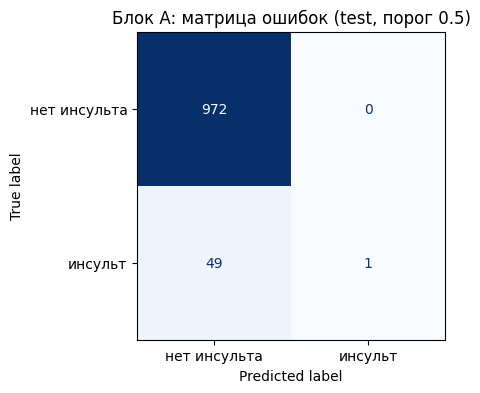

In [8]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["нет инсульта", "инсульт"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Блок A: матрица ошибок (test, порог 0.5)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}: здоровым пациентам правильно сказали «риска нет». Они спокойно идут домой.")
print(f"FP = {fp}: здоровых ошибочно отправили на обследование. Лишние расходы поликлиники, но вреда здоровью нет.")
print(f"FN = {fn}: пациенты с инсультом, которых модель ПРОПУСТИЛА. Самая опасная ошибка: человек не получит помощь вовремя.")
print(f"TP = {tp}: пациентов с инсультом модель правильно выбрала на обследование.")

### Вывод по блоку A

Точность (accuracy) получилась высокой, но она **обманчива**. Модель, которая всем отвечает «инсульта не будет», получила бы почти такую же точность (~95%) и не нашла бы ни одного больного. Смотрим на матрицу: FN почти равно числу всех больных, а TP близко к нулю. Для поликлиники такая модель бесполезна, потому что она не находит тех, ради кого всё затевалось. Поэтому в блоках B и C мы выбираем **другую метрику** (recall, F2, PR-AUC) и **подбираем порог**.

---
# БЛОК B. Основной

## B1. EDA: пропуски (в том числе скрытые), выбросы, подозрительные признаки

EDA (Exploratory Data Analysis) это разведка данных: ищем в них проблемы до того, как строить модель. Работаем с копией `eda`, чтобы не испортить исходные данные.

In [9]:
eda = df.copy()

# --- 1) Явные пропуски (NaN) ---
print("Явные пропуски (NaN):")
print(eda.isna().sum()[lambda s: s > 0])
print(f"bmi: пропущено {eda['bmi'].isna().mean():.1%}")

# --- 2) Скрытые пропуски: в категориях пропуск может быть записан словом ---
print("\nsmoking_status (смотрим на значение 'Unknown'):")
print(eda["smoking_status"].value_counts())
print(f"'Unknown' = {(eda['smoking_status'] == 'Unknown').mean():.1%} всех пациентов. Это фактически пропуск, просто записанный словом.")

Явные пропуски (NaN):
bmi    201
dtype: int64
bmi: пропущено 3.9%

smoking_status (смотрим на значение 'Unknown'):
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64
'Unknown' = 30.2% всех пациентов. Это фактически пропуск, просто записанный словом.


In [10]:
def stroke_rate(mask, name):
    return {"группа": name, "пациентов": int(mask.sum()),
            "инсультов": int(eda.loc[mask, "stroke"].sum()),
            "доля инсульта, %": round(eda.loc[mask, "stroke"].mean() * 100, 2)}

pd.DataFrame([
    stroke_rate(eda["bmi"].isna(),                    "bmi ПРОПУЩЕН"),
    stroke_rate(eda["bmi"].notna(),                   "bmi известен"),
    stroke_rate(eda["smoking_status"] == "Unknown",   "курение = Unknown"),
    stroke_rate(eda["smoking_status"] != "Unknown",   "курение известно"),
])

              группа  пациентов  инсультов  доля инсульта, %
0       bmi ПРОПУЩЕН        201         40             19.90
1       bmi известен       4909        209              4.26
2  курение = Unknown       1544         47              3.04
3   курение известно       3566        202              5.66

In [11]:
eda["age_group"] = pd.cut(eda["age"], [-1, 17, 39, 59, 74, 100], labels=["0-17", "18-39", "40-59", "60-74", "75+"])

print("Доля каждого статуса курения внутри возрастной группы:")
print(pd.crosstab(eda["age_group"], eda["smoking_status"], normalize="index").round(2))

Доля каждого статуса курения внутри возрастной группы:
smoking_status  Unknown  formerly smoked  never smoked  smokes
age_group                                                     
0-17               0.80             0.03          0.16    0.01
18-39              0.23             0.12          0.45    0.20
40-59              0.19             0.20          0.40    0.21
60-74              0.17             0.29          0.37    0.16
75+                0.21             0.27          0.42    0.10


**Находки про пропуски:**
1. У пациентов с пропущенным `bmi` инсульт случается примерно **в 5 раз чаще** (около 20% против 4%). Пропуск здесь не случаен, он сам несёт информацию, поэтому при заполнении медианой добавим флаг «bmi был пропущен».
2. `Unknown` в `smoking_status` это скрытый пропуск (30% данных). Больше всего их у детей: около 80% пациентов до 18 лет, то есть «Unknown» частично означает «ребёнка про курение не спрашивали». Выбрасывать эти строки нельзя, поэтому оставляем `Unknown` отдельной категорией.

In [12]:
# --- 3) Выбросы и странные значения ---
print(eda[["age", "avg_glucose_level", "bmi"]].describe().round(1))

for c in ["age", "avg_glucose_level", "bmi"]:
    q1, q3 = eda[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((eda[c] < q1 - 1.5 * iqr) | (eda[c] > q3 + 1.5 * iqr)).sum()
    print(f"{c}: выбросов по правилу 1.5*IQR = {n_out}")

print()
print("bmi > 60:", (eda["bmi"] > 60).sum(), "| bmi < 14:", (eda["bmi"] < 14).sum(), "| макс. bmi:", eda["bmi"].max())
print("avg_glucose_level > 200:", (eda["avg_glucose_level"] > 200).sum(),
      "| доля инсульта среди них, %:", round(eda.loc[eda["avg_glucose_level"] > 200, "stroke"].mean() * 100, 1))

          age  avg_glucose_level     bmi
count  5110.0             5110.0  4909.0
mean     43.2              106.1    28.9
std      22.6               45.3     7.9
min       0.0               55.1    10.3
25%      25.0               77.2    23.5
50%      45.0               91.9    28.1
75%      61.0              114.1    33.1
max      82.0              271.7    97.6
age: выбросов по правилу 1.5*IQR = 0
avg_glucose_level: выбросов по правилу 1.5*IQR = 627
bmi: выбросов по правилу 1.5*IQR = 110

bmi > 60: 13 | bmi < 14: 16 | макс. bmi: 97.6
avg_glucose_level > 200: 434 | доля инсульта среди них, %: 12.9


In [13]:
# --- 4) Подозрительные признаки и строки ---
print("id уникальны:", eda["id"].is_unique, "| полных дубликатов строк:", eda.duplicated().sum())
print("Связь id с инсультом (ROC-AUC, 0.5 = связи нет):", round(roc_auc_score(eda["stroke"], eda["id"]), 3))
print()
print("gender:", eda["gender"].value_counts().to_dict())
print("Возраст по типам работы:")
print(eda.groupby("work_type")["age"].agg(["count", "min", "median", "max"]))
print()
print("Несовершеннолетние с ever_married = Yes:", ((eda["age"] < 18) & (eda["ever_married"] == "Yes")).sum())
print("Пациентов младше 2 лет:", (eda["age"] < 2).sum())

id уникальны: True | полных дубликатов строк: 0
Связь id с инсультом (ROC-AUC, 0.5 = связи нет): 0.509

gender: {'Female': 2994, 'Male': 2115, 'Other': 1}
Возраст по типам работы:
               count  min  median  max
work_type                             
Govt_job         657   14    51.0   82
Never_worked      22   13    16.0   23
Private         2925    8    45.0   82
Self-employed    819    7    63.0   82
children         687    0     6.0   16

Несовершеннолетние с ever_married = Yes: 0
Пациентов младше 2 лет: 120


In [14]:
# --- 5) Какие признаки вообще связаны с инсультом? (хи-квадрат, p < 0.05 = связь есть) ---
rows = []
for c in ["gender", "ever_married", "work_type", "Residence_type", "smoking_status", "hypertension", "heart_disease"]:
    p = chi2_contingency(pd.crosstab(eda[c], eda["stroke"]))[1]
    rows.append({"признак": c, "p-value": round(p, 4), "связь с инсультом": "ДА" if p < 0.05 else "нет"})
pd.DataFrame(rows)

          признак  p-value связь с инсультом
0          gender   0.7895               нет
1    ever_married   0.0000                ДА
2       work_type   0.0000                ДА
3  Residence_type   0.2983               нет
4  smoking_status   0.0000                ДА
5    hypertension   0.0000                ДА
6   heart_disease   0.0000                ДА

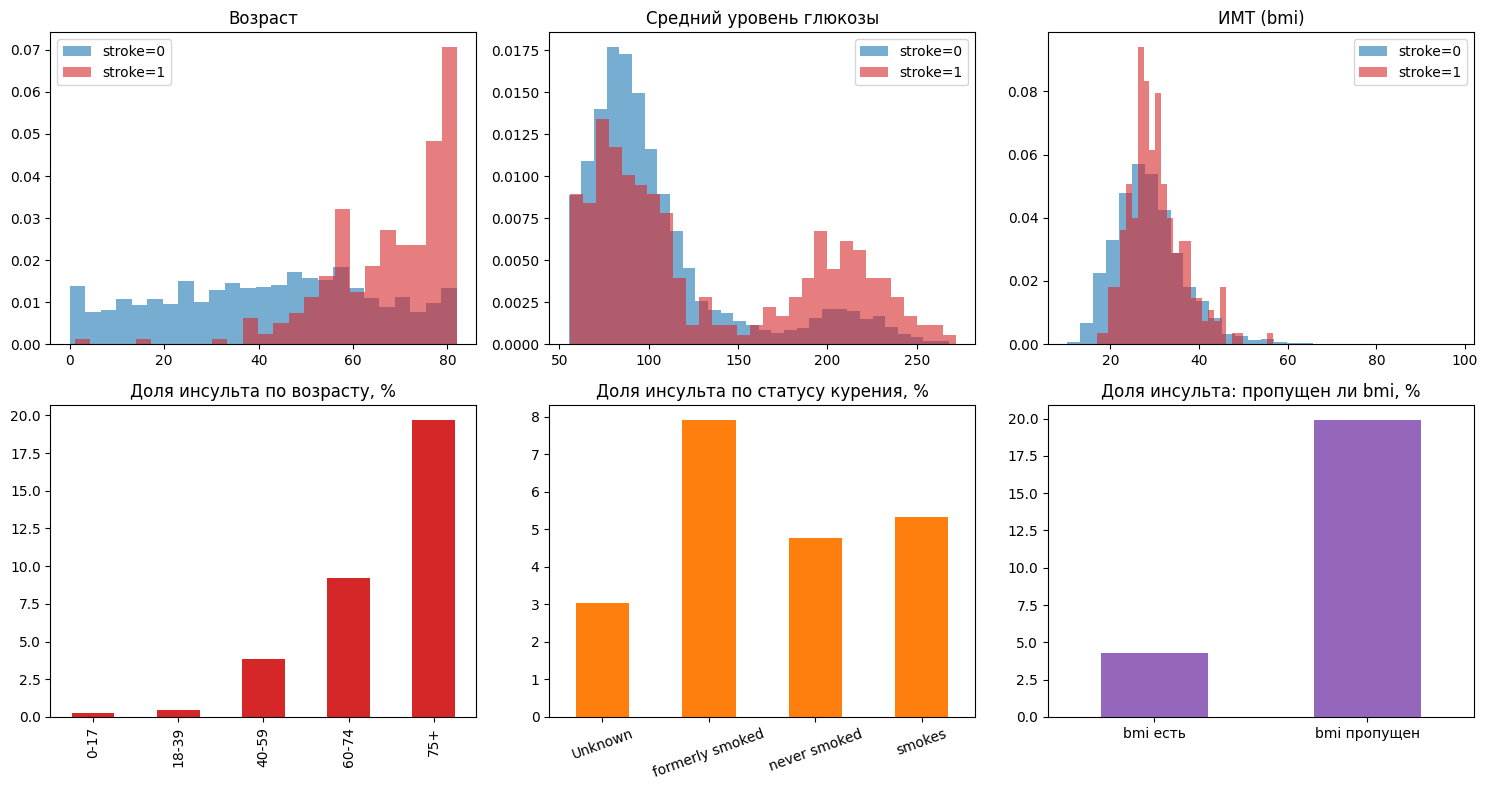

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for lab, color in [(0, "tab:blue"), (1, "tab:red")]:
    axes[0, 0].hist(eda.loc[eda.stroke == lab, "age"], bins=25, alpha=.6, color=color, density=True, label=f"stroke={lab}")
    axes[0, 1].hist(eda.loc[eda.stroke == lab, "avg_glucose_level"], bins=30, alpha=.6, color=color, density=True, label=f"stroke={lab}")
    axes[0, 2].hist(eda.loc[eda.stroke == lab, "bmi"].dropna(), bins=30, alpha=.6, color=color, density=True, label=f"stroke={lab}")
for ax, t in zip(axes[0], ["Возраст", "Средний уровень глюкозы", "ИМТ (bmi)"]):
    ax.set_title(t); ax.legend()

(eda.groupby("age_group", observed=True)["stroke"].mean() * 100).plot.bar(ax=axes[1, 0], color="tab:red")
axes[1, 0].set_title("Доля инсульта по возрасту, %"); axes[1, 0].set_xlabel("")

(eda.groupby("smoking_status")["stroke"].mean() * 100).plot.bar(ax=axes[1, 1], color="tab:orange")
axes[1, 1].set_title("Доля инсульта по статусу курения, %"); axes[1, 1].set_xlabel(""); axes[1, 1].tick_params(axis="x", rotation=20)

(eda.assign(bmi_missing=eda.bmi.isna().map({True: "bmi пропущен", False: "bmi есть"}))
    .groupby("bmi_missing")["stroke"].mean() * 100).plot.bar(ax=axes[1, 2], color="tab:purple")
axes[1, 2].set_title("Доля инсульта: пропущен ли bmi, %"); axes[1, 2].set_xlabel(""); axes[1, 2].tick_params(axis="x", rotation=0)

plt.tight_layout(); plt.show()

**Итоги EDA:**

- **Возраст** главный фактор: после 60 лет доля инсульта резко растёт. Высокий уровень глюкозы, гипертония и болезни сердца тоже связаны с инсультом.
- **Выбросы:** в `bmi` есть нереальные значения (максимум 97,6, есть и меньше 14). Мы **ограничим** `bmi` диапазоном 12–60, а не будем удалять строки (мало данных и мало больных). Высокая глюкоза (>200) это не ошибка, а реальный медицинский признак, её оставляем.
- **Подозрительное:** `id` не связан с инсультом (AUC ≈ 0.5), это просто номер. В `gender` есть **1 строка со значением `Other`**, для обучения этого мало. Тип работы `children` почти полностью повторяет «возраст < 17», а `Never_worked` почти всегда подростки. То есть `work_type` и `ever_married` частично дублируют возраст.
- **Дубликатов строк нет.**

## B2. Pipeline + ColumnTransformer без утечек. Лишние признаки удаляем с объяснением

**Какие признаки удаляем и почему**

| Признак | Решение | Объяснение |
|---|---|---|
| `id` | удалён ещё в блоке A | номер записи, при применении модели к новому пациенту смысла не имеет, связи с инсультом нет |
| `Residence_type` | **удаляем** | тест хи-квадрат не нашёл связи с инсультом, а медицински «город или село» для оценки риска вторичен. Лишний признак добавляет шум |

Остальные признаки оставляем. `gender`, `work_type` и `ever_married` частично дублируют возраст, но поликлиника их знает, и они не вредят.

**Как избегаем утечек:**
1. Разбиение train/test сделано до всего остального.
2. Заполнение пропусков, масштаб и кодирование находятся **внутри Pipeline**, поэтому в кросс-валидации обучаются только на train-части каждого фолда.
3. Ограничение `bmi` диапазоном 12–60 это фиксированное правило, оно ничего не берёт из данных.
4. Порог выбираем по кросс-валидации на train, а **тест открываем один раз** в самом конце.

In [16]:
FEATURES_B = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi",
              "gender", "ever_married", "work_type", "smoking_status"]     # без id и Residence_type

XB_train, XB_test = X_train[FEATURES_B], X_test[FEATURES_B]

def clip_bmi(x):
    """Фиксированное правило: нереалистичные значения bmi обрезаем до 12..60 (NaN остаётся NaN)."""
    return np.clip(x, 12, 60)

def make_preprocessor(bmi_indicator=True):
    return ColumnTransformer([
        ("num", StandardScaler(), ["age", "avg_glucose_level"]),
        ("bmi", Pipeline([("clip", FunctionTransformer(clip_bmi)),
                          ("imp", SimpleImputer(strategy="median", add_indicator=bmi_indicator)),   # + флаг "bmi был пропущен"
                          ("sc", StandardScaler())]), ["bmi"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["gender", "ever_married", "work_type", "smoking_status"]),
        ("bin", "passthrough", ["hypertension", "heart_disease"]),
    ], remainder="drop")

def make_model(name, class_weight=None, bmi_indicator=True):
    if name == "LogReg":
        clf = LogisticRegression(max_iter=1000, class_weight=class_weight)
    elif name == "RandomForest":
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1,
                                     class_weight="balanced_subsample" if class_weight else None)
    return Pipeline([("prep", make_preprocessor(bmi_indicator)), ("clf", clf)])

make_model("LogReg")

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'avg_glucose_level']),
                                                 ('bmi',
                                                  Pipeline(steps=[('clip',
                                                                   FunctionTransformer(func=<function clip_bmi at 0x7feda123fba0>)),
                                                                  ('imp',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['bmi']),
                                                 ('cat',

## B3. Две модели, `StratifiedKFold(5)` на train, итог на отложенном тесте

Берём две разные по духу модели:
- **LogisticRegression**: простая, понятная, её легко объяснить врачу;
- **RandomForest**: ансамбль деревьев, умеет ловить нелинейные зависимости.

`StratifiedKFold(5)` делит train на 5 частей с сохранением доли больных. Каждая часть по очереди служит проверочной, а на остальных четырёх модель учится.

In [17]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def f2(y_true, y_pred):                       # F2: recall важнее precision (в 4 раза), т.к. пропустить больного хуже, чем лишний раз обследовать
    return fbeta_score(y_true, y_pred, beta=2, zero_division=0)

scoring = {
    "ROC-AUC":   "roc_auc",
    "PR-AUC":    "average_precision",
    "recall":    make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "F2":        make_scorer(f2),
}

rows = []
for name in ["LogReg", "RandomForest"]:
    res = cross_validate(make_model(name), XB_train, y_train, cv=cv5, scoring=scoring)
    row = {"модель": name}
    for m in scoring:
        row[m] = f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}"
    rows.append(row)

print("Кросс-валидация на train (среднее ± разброс по 5 фолдам), порог по умолчанию 0.5:")
pd.DataFrame(rows).set_index("модель")

Кросс-валидация на train (среднее ± разброс по 5 фолдам), порог по умолчанию 0.5:


                    ROC-AUC         PR-AUC         recall      precision             F2
модель                                                                                 
LogReg        0.852 ± 0.009  0.233 ± 0.041  0.010 ± 0.012  0.250 ± 0.387  0.012 ± 0.015
RandomForest  0.848 ± 0.017  0.246 ± 0.047  0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000

При пороге 0.5 `recall` почти нулевой: модели редко «решаются» назвать пациента рискованным, потому что больных всего 5%. А вот **ROC-AUC и PR-AUC** (они от порога не зависят) показывают, что ранжировать пациентов по риску модели умеют. Значит, проблема в пороге, а не в самой модели. Подберём его.

## B4. Метрика под заказчика и подбор порога

**Что важно заказчику.** Обследование недорогое, а пропущенный больной это потенциально тяжёлые последствия. Поэтому:
- главная метрика: **recall** (какую долю будущих инсультов мы поймали), но не любой ценой;
- чтобы не отправлять на обследование вообще всех, берём **F2-меру**: она учитывает и recall, и precision, но recall важнее в 4 раза;
- дополнительно смотрим **PR-AUC** (качество ранжирования при редком классе) и **долю пациентов, отправленных на обследование**: это то, что платит поликлиника.

**Порог** выбираем так: получаем «честные» вероятности для каждого пациента из train через кросс-валидацию (`cross_val_predict`, модель его не видела) и берём порог с максимальным F2. Тест при этом не используется.

In [18]:
oof = {}
for name in ["LogReg", "RandomForest"]:
    oof[name] = cross_val_predict(make_model(name), XB_train, y_train, cv=cv5, method="predict_proba")[:, 1]

thr_grid = np.arange(0.01, 0.60, 0.005)

def best_threshold(y_true, proba):
    scores = [f2(y_true, (proba >= t).astype(int)) for t in thr_grid]
    i = int(np.argmax(scores))
    return thr_grid[i], scores[i], scores

best = {}
rows = []
for name, p in oof.items():
    t, s, _ = best_threshold(y_train, p)
    pred = (p >= t).astype(int)
    best[name] = t
    rows.append({"модель": name, "PR-AUC": round(average_precision_score(y_train, p), 3),
                 "лучший порог": round(t, 3), "F2": round(s, 3),
                 "recall": round(recall_score(y_train, pred), 3),
                 "precision": round(precision_score(y_train, pred), 3),
                 "отправлено на обследование, %": round(pred.mean() * 100, 1)})
pd.DataFrame(rows).set_index("модель")

              PR-AUC  лучший порог     F2  recall  precision  отправлено на обследование, %
модель                                                                                     
LogReg         0.210         0.090  0.428   0.653      0.180                           17.7
RandomForest   0.226         0.085  0.432   0.714      0.167                           20.7

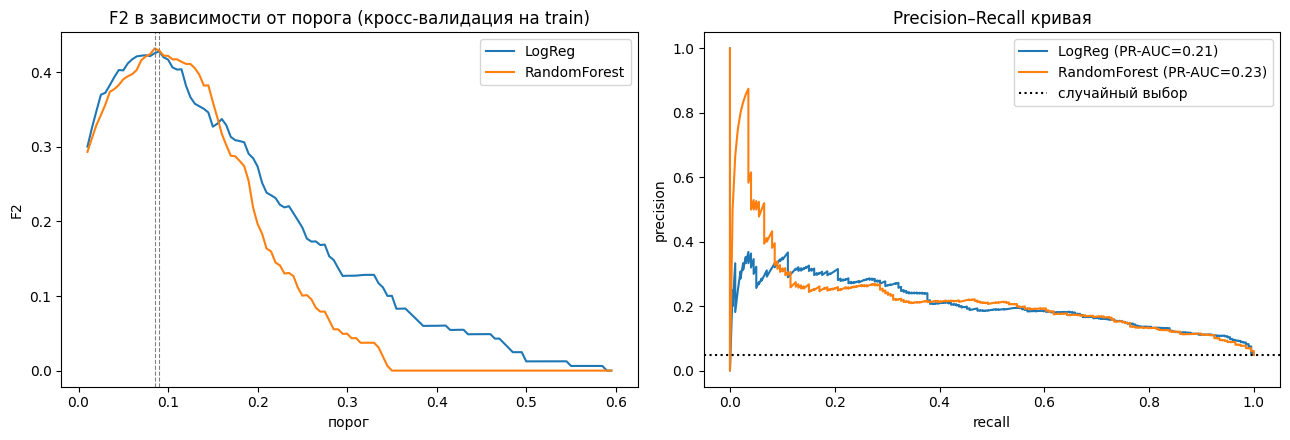

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in oof.items():
    _, _, sc = best_threshold(y_train, p)
    axes[0].plot(thr_grid, sc, label=name)
    axes[0].axvline(best[name], ls="--", lw=.8, color="gray")
    pr, rc, _ = precision_recall_curve(y_train, p)
    axes[1].plot(rc, pr, label=f"{name} (PR-AUC={average_precision_score(y_train, p):.2f})")
axes[0].set_xlabel("порог"); axes[0].set_ylabel("F2"); axes[0].set_title("F2 в зависимости от порога (кросс-валидация на train)"); axes[0].legend()
axes[1].axhline(y_train.mean(), ls=":", color="k", label="случайный выбор")
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision–Recall кривая"); axes[1].legend()
plt.tight_layout(); plt.show()

In [20]:
# Таблица для поликлиники: "если порог такой, то..." (LogReg, честные вероятности на train)
def threshold_table(y_true, proba, thresholds):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        rows.append({"порог": t, "поймано инсультов (recall), %": round(recall_score(y_true, pred) * 100, 1),
                     "из отобранных реально больны (precision), %": round(precision_score(y_true, pred, zero_division=0) * 100, 1),
                     "отправлено на обследование, % пациентов": round(pred.mean() * 100, 1)})
    return pd.DataFrame(rows).set_index("порог")

threshold_table(y_train, oof["LogReg"], [0.03, 0.05, 0.07, 0.10, 0.15, 0.20, 0.30])

       поймано инсультов (recall), %  из отобранных реально больны (precision), %  отправлено на обследование, % пациентов
порог                                                                                                                     
0.03                            89.4                                         11.2                                     39.0
0.05                            78.4                                         13.7                                     27.9
0.07                            70.9                                         16.1                                     21.4
0.10                            61.3                                         18.3                                     16.3
0.15                            38.2                                         20.8                                      9.0
0.20                            27.1                                         28.3                                      4.7
0.30            

## B5. Итог на отложенном тесте и вывод

Выбираем модель по лучшему F2 на кросс-валидации и **один раз** проверяем на тесте с уже выбранным порогом.

In [21]:
def evaluate(pipe, thr, Xtr, ytr, Xte, yte):
    pipe.fit(Xtr, ytr)
    proba = pipe.predict_proba(Xte)[:, 1]
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    return proba, pred, {"ROC-AUC": round(roc_auc_score(yte, proba), 3), "PR-AUC": round(average_precision_score(yte, proba), 3),
                         "recall": round(recall_score(yte, pred), 3), "precision": round(precision_score(yte, pred, zero_division=0), 3),
                         "F2": round(f2(yte, pred), 3), "отправлено на обследование, %": round(pred.mean() * 100, 1),
                         "TN": tn, "FP": fp, "FN": fn, "TP": tp}

cv_f2 = {n: best_threshold(y_train, oof[n])[1] for n in oof}
print("F2 на кросс-валидации:", {n: round(v, 3) for n, v in cv_f2.items()})

# Правило выбора (без подглядывания в тест): берём лучшую по F2;
# если разница меньше 0.02, это в пределах шума, и мы выбираем более простую и объяснимую LogReg.
final_name = max(cv_f2, key=cv_f2.get)
if abs(cv_f2["LogReg"] - cv_f2["RandomForest"]) < 0.02:
    final_name = "LogReg"
print("Выбранная модель:", final_name, "| порог:", round(best[final_name], 3))

rows = []
for name in ["LogReg", "RandomForest"]:
    _, _, m = evaluate(make_model(name), best[name], XB_train, y_train, XB_test, y_test)
    rows.append({"модель": name, **m})
pd.DataFrame(rows).set_index("модель")

F2 на кросс-валидации: {'LogReg': 0.428, 'RandomForest': 0.432}
Выбранная модель: LogReg | порог: 0.09


              ROC-AUC  PR-AUC  recall  precision     F2  отправлено на обследование, %   TN   FP  FN  TP
модель                                                                                                  
LogReg          0.843   0.259    0.72      0.200  0.474                           17.6  828  144  14  36
RandomForest    0.835   0.235    0.72      0.175  0.443                           20.2  802  170  14  36

Из 50 пациентов с инсультом на тесте модель нашла 36, пропустила 14.
Ради этого на обследование отправлено 17.6% пациентов, из них лишних (FP): 144.


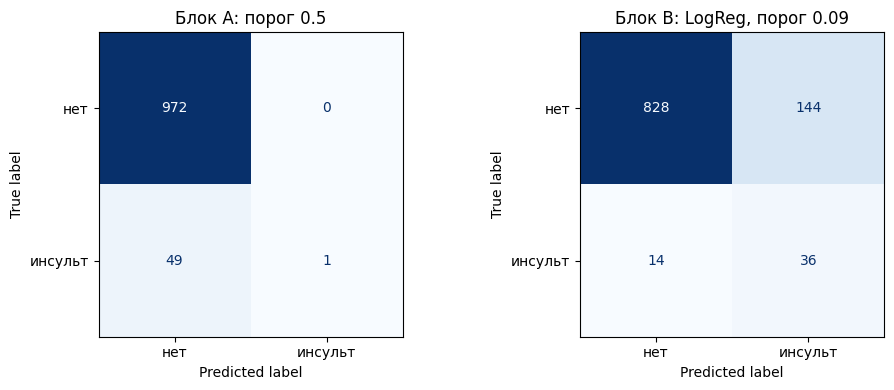

In [22]:
proba_b, pred_b, m_b = evaluate(make_model(final_name), best[final_name], XB_train, y_train, XB_test, y_test)
cm_b = confusion_matrix(y_test, pred_b)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=["нет", "инсульт"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Блок A: порог 0.5")
ConfusionMatrixDisplay(cm_b, display_labels=["нет", "инсульт"]).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title(f"Блок B: {final_name}, порог {best[final_name]:.2f}")
plt.tight_layout(); plt.show()

print(f"Из {int(y_test.sum())} пациентов с инсультом на тесте модель нашла {m_b['TP']}, пропустила {m_b['FN']}.")
print(f"Ради этого на обследование отправлено {m_b['отправлено на обследование, %']}% пациентов, из них лишних (FP): {m_b['FP']}.")

### Вывод по блоку B: можно ли отдавать модель поликлинике?

**Что получилось (отложенный тест, 1022 пациента, из них 50 с инсультом; LogReg, порог 0.09):**

| Показатель | Значение | Что это значит для поликлиники |
|---|---|---|
| Найдено больных (recall) | 36 из 50 = **72%** | модель находит примерно 7 из 10 будущих «инсультных» пациентов |
| Пропущено (FN) | 14 из 50 | 3 из 10 больных модель не заметит |
| Отправлено на обследование | **17,6%** пациентов | это и есть нагрузка на поликлинику |
| Из отобранных больны (precision) | 20% | 4 из 5 отобранных здоровы. Обследование недорогое, поэтому это терпимо |
| Выигрыш против случайного отбора | ~4 раза | случайный отбор тех же 17,6% нашёл бы ~9 больных, а модель нашла 36 |

В блоке A (порог 0.5) модель находила **1 больного из 50**, теперь находит 36. Модель не стала «умнее»: мы выбрали порог под задачу заказчика.

**Можно ли отдавать модель? Да, но только как вспомогательный инструмент первичного отбора, а не как диагноз, и с оговорками:**
1. Она **пропускает около 28% больных**. Тот, кого модель не выбрала, не «здоров», он просто не попал в список. Обычную диспансеризацию для остальных отменять нельзя.
2. Оценка неточная: на тесте всего 50 больных. 95% доверительный интервал для recall: примерно **60–84%** (см. C2).
3. Порог 0.09 это компромисс. Если у поликлиники больше денег и мест, порог можно снизить (таблица выше: при пороге 0.05 находим 78% больных, но обследуем 28% пациентов). Решение за заказчиком.
4. Как выяснится в блоке C, модель в основном опирается на **возраст**, и молодых больных она находит плохо.
5. Данные учебные, происхождение неизвестно, внешней проверки не было.

---
# БЛОК C. Продвинутый

## C1. Все проблемы данных и потенциальные утечки: что, как нашли, что сделали

| # | Проблема | Как нашли | Что сделали |
|---|---|---|---|
| 1 | **Сильный дисбаланс классов** (4,9% инсультов) | `value_counts` по `stroke` | `stratify` при разбиении, `StratifiedKFold`, метрики recall / F2 / PR-AUC вместо accuracy, подбор порога, методы борьбы с дисбалансом (C2) |
| 2 | **Столбец `id`** | уникален, смысла нет, связь с инсультом ≈ 0 (AUC 0.51) | удалён до любой обработки |
| 3 | **Явные пропуски `bmi`** (3,9%) | `isna().sum()` | медиана внутри Pipeline (fit только на train) |
| 4 | **Пропуск `bmi` несёт информацию**: среди таких пациентов 19,9% инсультов против 4,3% | сравнили долю инсульта в группах | добавили флаг «bmi был пропущен» (`add_indicator=True`) и проверили, не опасен ли он (ниже) |
| 5 | **Скрытые пропуски**: `smoking_status = "Unknown"` (30%), особенно у детей | `value_counts`, таблица по возрастам | оставили как отдельную категорию, строки не выбрасывали |
| 6 | **Выбросы `bmi`** (до 97,6; есть значения меньше 14) | `describe`, правило IQR | ограничение (clip) диапазоном 12–60 внутри Pipeline |
| 7 | **Высокая глюкоза** (>200, 434 человека) | `describe`, IQR | **не** трогали: это медицинский сигнал (среди них 12,9% инсультов), а не ошибка |
| 8 | **Одна строка `gender = Other`** | `value_counts` | оставили, `OneHotEncoder(handle_unknown="ignore")` не падает на редких категориях |
| 9 | **Признаки-дубликаты возраста**: `work_type = children`, `ever_married` | таблица возраст × тип работы | оставили, но помним об этом в анализе ошибок |
| 10 | **Бесполезный `Residence_type`** | хи-квадрат, p ≈ 0.30 | удалили из модели |
| 11 | **Утечка: заполнение/масштаб до разбиения** | теоретически | всё внутри Pipeline, разбиение первым шагом |
| 12 | **Утечка: подбор порога по тесту** | теоретически | порог выбираем по кросс-валидации на train, тест открываем один раз |
| 13 | **Утечка: oversampling ДО кросс-валидации** | показываем экспериментом ниже | все методы борьбы с дисбалансом применяются **только к обучающей части каждого фолда** |
| 14 | **Утечка по времени/причине**: неизвестно, когда измерены признаки (до или после инсульта) | в описании данных этого нет | не можем проверить; фиксируем как ограничение (C4) |

### Вспомогательные функции для блока C

Методы борьбы с дисбалансом пишем вручную (библиотеки `imbalanced-learn` не требуем). Главное правило: **изменять баланс классов можно только в обучающей части фолда, проверочная часть остаётся «как в жизни»**.

In [23]:
def random_oversample(X, y, seed=RANDOM_STATE):
    """Дублирует случайных больных, пока их не станет столько же, сколько здоровых."""
    rng = np.random.RandomState(seed)
    pos, neg = np.where(y.values == 1)[0], np.where(y.values == 0)[0]
    extra = rng.choice(pos, size=len(neg) - len(pos), replace=True)
    idx = rng.permutation(np.concatenate([neg, pos, extra]))
    return X.iloc[idx], y.iloc[idx]

def random_undersample(X, y, seed=RANDOM_STATE):
    """Оставляет всех больных и такое же число случайных здоровых."""
    rng = np.random.RandomState(seed)
    pos, neg = np.where(y.values == 1)[0], np.where(y.values == 0)[0]
    keep = rng.permutation(np.concatenate([pos, rng.choice(neg, size=len(pos), replace=False)]))
    return X.iloc[keep], y.iloc[keep]

def make_fitted(name, method, Xtr, ytr, seed=RANDOM_STATE, bmi_indicator=True):
    """Применяет метод к ОБУЧАЮЩЕЙ части и обучает модель."""
    if method == "oversampling":
        Xtr, ytr = random_oversample(Xtr, ytr, seed)
    elif method == "undersampling":
        Xtr, ytr = random_undersample(Xtr, ytr, seed)
    model = make_model(name, class_weight="balanced" if method == "class_weight" else None, bmi_indicator=bmi_indicator)
    return model.fit(Xtr, ytr)

def cv_oof(name, method, X, y, cv=cv5, bmi_indicator=True):
    """Кросс-валидация: возвращает честные вероятности для каждого пациента и F2 (порог 0.5) по фолдам."""
    oof, fold_f2 = np.zeros(len(y)), []
    for k, (tr, va) in enumerate(cv.split(X, y)):
        model = make_fitted(name, method, X.iloc[tr], y.iloc[tr], seed=RANDOM_STATE + k, bmi_indicator=bmi_indicator)
        p = model.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p
        fold_f2.append(f2(y.iloc[va], (p >= 0.5).astype(int)))
    return oof, fold_f2

### Эксперимент 1. Как выглядит утечка из-за oversampling до кросс-валидации

Сравниваем два способа оценить одну и ту же модель (RandomForest + oversampling):
- **Неправильно:** сначала размножили больных во всём train, потом запустили кросс-валидацию. Копии одного и того же больного попадают и в обучающую, и в проверочную часть, и модель просто «узнаёт» их.
- **Правильно:** размножаем только обучающую часть каждого фолда.

In [24]:
# НЕПРАВИЛЬНО: oversampling до кросс-валидации
X_os, y_os = random_oversample(XB_train, y_train)
p_wrong = cross_val_predict(make_model("RandomForest"), X_os, y_os, cv=cv5, method="predict_proba")[:, 1]

# ПРАВИЛЬНО: oversampling внутри фолда
p_right, _ = cv_oof("RandomForest", "oversampling", XB_train, y_train)

print("                          ROC-AUC   recall при пороге 0.5")
print(f"НЕПРАВИЛЬНО (утечка):      {roc_auc_score(y_os, p_wrong):.3f}     {recall_score(y_os, p_wrong >= .5):.3f}")
print(f"ПРАВИЛЬНО:                 {roc_auc_score(y_train, p_right):.3f}     {recall_score(y_train, p_right >= .5):.3f}")

                          ROC-AUC   recall при пороге 0.5
НЕПРАВИЛЬНО (утечка):      0.987     0.994
ПРАВИЛЬНО:                 0.845     0.538


**Вывод.** Из-за утечки метрики выглядят «космически» (ROC-AUC 0.99, recall 99%), а честная оценка гораздо скромнее (0.85 и 54%). Если бы мы сделали oversampling до кросс-валидации, то отчитались бы перед заказчиком о модели, которой на самом деле нет. **Правило: любые преобразования, меняющие данные (заполнение пропусков, масштаб, oversampling, подбор порога), делаются только на обучающей части.**

### Эксперимент 2. Не опасен ли флаг «bmi пропущен» и сколько в модели от одного возраста?

Среди пациентов с пропущенным `bmi` инсульт встречается в 5 раз чаще. Это может быть реальный сигнал, а может быть **артефакт сбора данных** (например, у тяжёлых пациентов bmi не измеряли). В поликлинике у нового пациента причина пропуска будет другой. Проверим, сколько этот флаг даёт модели. Заодно сравним с моделью, которая знает **только возраст**.

In [25]:
rows = []
for label, kw, cols in [("LogReg, все признаки + флаг bmi (наша модель)", dict(bmi_indicator=True), FEATURES_B),
                        ("LogReg, все признаки, БЕЗ флага bmi",         dict(bmi_indicator=False), FEATURES_B)]:
    p, _ = cv_oof("LogReg", "none", XB_train[cols], y_train, **kw)
    t, s, _ = best_threshold(y_train, p)
    rows.append({"вариант": label, "ROC-AUC": round(roc_auc_score(y_train, p), 3),
                 "PR-AUC": round(average_precision_score(y_train, p), 3), "F2 (лучший порог)": round(s, 3)})

age_only = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression())])
p = cross_val_predict(age_only, XB_train[["age"]], y_train, cv=cv5, method="predict_proba")[:, 1]
rows.append({"вариант": "LogReg только по возрасту", "ROC-AUC": round(roc_auc_score(y_train, p), 3),
             "PR-AUC": round(average_precision_score(y_train, p), 3), "F2 (лучший порог)": round(best_threshold(y_train, p)[1], 3)})
pd.DataFrame(rows).set_index("вариант")

                                               ROC-AUC  PR-AUC  F2 (лучший порог)
вариант                                                                          
LogReg, все признаки + флаг bmi (наша модель)    0.852   0.210              0.428
LogReg, все признаки, БЕЗ флага bmi              0.839   0.171              0.408
LogReg только по возрасту                        0.834   0.160              0.390

**Выводы:**
- Флаг «bmi пропущен» немного улучшает модель (PR-AUC 0.17 → 0.21, F2 0.41 → 0.43). Мы его **оставляем**, но с оговоркой: непонятно, **почему** bmi не измерили. Если у пациентов с тяжёлым состоянием его пропускали, то это артефакт сбора данных, а не медицинский признак. В поликлинике, где bmi измеряют всем, флаг всегда будет «0», и этот небольшой плюс исчезнет (модель надо будет переобучить без флага, потеря небольшая).
- **Модель почти целиком держится на возрасте.** Модель только по возрасту даёт ROC-AUC 0.83, а все признаки вместе 0.85. Остальные признаки добавляют немного, и это нужно честно сказать заказчику.

## C2. Не менее двух методов против дисбаланса внутри кросс-валидации. Сравнение по метрике заказчика

Сравниваем **четыре подхода** на двух моделях (все внутри `StratifiedKFold(5)` на train):

1. **Без балансировки**, только подбор порога (базовый вариант);
2. **`class_weight`**: ошибка на больном «стоит» дороже, модель сама старается их не пропускать;
3. **Oversampling**: размножаем больных в обучающей части фолда;
4. **Undersampling**: выбрасываем часть здоровых в обучающей части фолда.

**Метрика заказчика: F2** (recall в 4 раза важнее precision). Показываем её двумя способами:
- **F2 при пороге 0.5** (среднее по фолдам): как метод работает «из коробки»;
- **F2 при лучшем пороге** (по честным вероятностям из кросс-валидации): как метод работает после подбора порога.

In [26]:
methods = {"без балансировки (порог)": "none", "class_weight": "class_weight",
           "oversampling": "oversampling", "undersampling": "undersampling"}

cv_results, rows = {}, []
for name in ["LogReg", "RandomForest"]:
    for label, m in methods.items():
        p, fold_f2 = cv_oof(name, m, XB_train, y_train)
        t, s, _ = best_threshold(y_train, p)
        pred = (p >= t).astype(int)
        cv_results[(name, m)] = (p, t, s)
        rows.append({"модель": name, "метод": label,
                     "PR-AUC": round(average_precision_score(y_train, p), 3),
                     "F2 при пороге 0.5": f"{np.mean(fold_f2):.3f} ± {np.std(fold_f2):.3f}",
                     "лучший порог": round(t, 3), "F2 при лучшем пороге": round(s, 3),
                     "recall": round(recall_score(y_train, pred), 3),
                     "precision": round(precision_score(y_train, pred), 3),
                     "отправлено, %": round(pred.mean() * 100, 1)})
cmp_df = pd.DataFrame(rows)
cmp_df

         модель                     метод  PR-AUC F2 при пороге 0.5  лучший порог  F2 при лучшем пороге  recall  precision  отправлено, %
0        LogReg  без балансировки (порог)   0.210     0.012 ± 0.015         0.090                 0.428   0.653      0.180           17.7
1        LogReg              class_weight   0.208     0.411 ± 0.018         0.530                 0.421   0.779      0.148           25.6
2        LogReg              oversampling   0.207     0.418 ± 0.017         0.550                 0.420   0.759      0.151           24.5
3        LogReg             undersampling   0.205     0.403 ± 0.019         0.585                 0.422   0.769      0.150           24.9
4  RandomForest  без балансировки (порог)   0.226     0.000 ± 0.000         0.085                 0.432   0.714      0.167           20.7
5  RandomForest              class_weight   0.210     0.402 ± 0.043         0.460                 0.430   0.653      0.182           17.5
6  RandomForest              overs

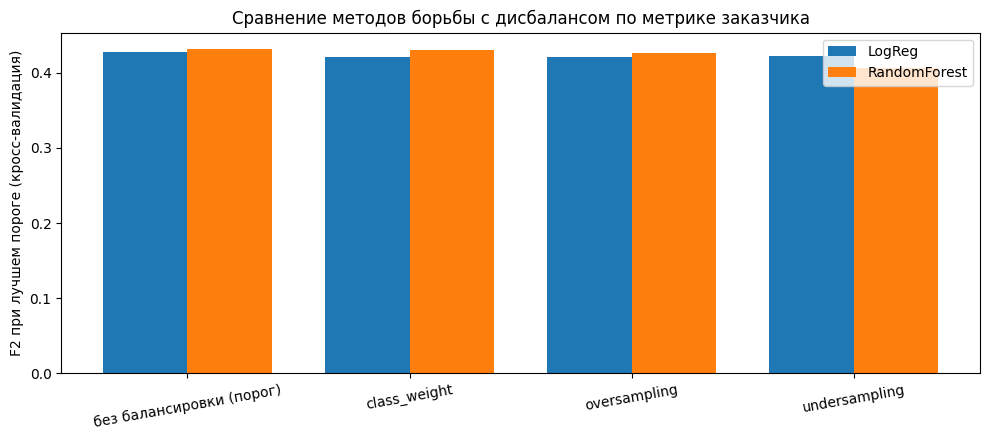

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.5))
w = 0.38
labels = list(methods.keys())
for i, name in enumerate(["LogReg", "RandomForest"]):
    vals = [cv_results[(name, m)][2] for m in methods.values()]
    ax.bar(np.arange(len(labels)) + (i - .5) * w, vals, w, label=name)
ax.set_xticks(np.arange(len(labels))); ax.set_xticklabels(labels, rotation=10)
ax.set_ylabel("F2 при лучшем пороге (кросс-валидация)"); ax.set_title("Сравнение методов борьбы с дисбалансом по метрике заказчика")
ax.legend(); plt.tight_layout(); plt.show()

In [28]:
# Выбор итогового варианта: лучший F2 при лучшем пороге (кросс-валидация, тест не используется)
cmp_sorted = cmp_df.sort_values("F2 при лучшем пороге", ascending=False)
print(cmp_sorted[["модель", "метод", "F2 при лучшем пороге", "recall", "precision", "отправлено, %"]].head(4).to_string(index=False))

      модель                    метод  F2 при лучшем пороге  recall  precision  отправлено, %
RandomForest без балансировки (порог)                 0.432   0.714      0.167           20.7
RandomForest             class_weight                 0.430   0.653      0.182           17.5
      LogReg без балансировки (порог)                 0.428   0.653      0.180           17.7
RandomForest             oversampling                 0.426   0.698      0.166           20.4


**Выводы по сравнению методов:**
1. **«Из коробки» (порог 0.5) методы очень помогают.** Без балансировки F2 ≈ 0.01 (модель молчит), а с `class_weight`, oversampling или undersampling F2 ≈ 0.38–0.42. По сути все эти методы **сдвигают решение модели** в сторону «лучше перестраховаться».
2. **После подбора порога разница почти исчезает:** F2 у всех вариантов около 0.41–0.43. Разброс между фолдами (± 0.02–0.05) больше, чем разница между методами, поэтому **явного победителя нет**.
3. PR-AUC (качество ранжирования) у балансировки **не растёт**. Балансировка не делает модель «умнее», она лишь двигает порог. Поэтому самый простой вариант (обычная LogReg + хорошо подобранный порог) нас устраивает.
4. Undersampling для RandomForest немного хуже остальных (F2 0.41): мы выбрасываем ~95% здоровых пациентов и теряем информацию.
5. Oversampling самый «опасный» метод: ошибся с порядком шагов и получил утечку (эксперимент 1).

**Выбираем LogReg без балансировки + порог по кросс-валидации.** Она проще и понятнее врачу, а качество не хуже. Если заказчик захочет, чтобы модель «из коробки» работала с порогом 0.5, можно использовать `class_weight="balanced"`.

### Итоговая модель блока C на отложенном тесте

Выбор делаем по кросс-валидации. Если несколько вариантов различаются меньше, чем на 0.02 по F2 (в пределах шума), берём более простой и объяснимый (LogReg), а из методов баланса тот, что даёт хорошие вероятности без лишнего усложнения.

In [29]:
top = cmp_df["F2 при лучшем пороге"].max()
cands = cmp_df[cmp_df["F2 при лучшем пороге"] >= top - 0.02]            # всё, что в пределах шума от лучшего
pick = cands[cands["модель"] == "LogReg"]
pick = (pick if len(pick) else cands).sort_values("F2 при лучшем пороге", ascending=False).iloc[0]

final_c_name, final_c_method = pick["модель"], methods[pick["метод"]]
p_oof_c, thr_c, _ = cv_results[(final_c_name, final_c_method)]
print(f"Выбрано: {final_c_name} + {pick['метод']}, порог {thr_c:.3f}  (кросс-валидация: F2 = {pick['F2 при лучшем пороге']})")

# Один раз обучаем на всём train и проверяем на тесте
model_c = make_fitted(final_c_name, final_c_method, XB_train, y_train)
proba_c = model_c.predict_proba(XB_test)[:, 1]
pred_c = (proba_c >= thr_c).astype(int)
cm_c = confusion_matrix(y_test, pred_c)
tn, fp, fn, tp = cm_c.ravel()

print()
print(f"TEST  recall = {recall_score(y_test, pred_c):.3f} | precision = {precision_score(y_test, pred_c):.3f} | F2 = {f2(y_test, pred_c):.3f}"
      f" | ROC-AUC = {roc_auc_score(y_test, proba_c):.3f} | PR-AUC = {average_precision_score(y_test, proba_c):.3f}")
print(f"Из {int(y_test.sum())} больных найдено {tp}, пропущено {fn}. Отправлено на обследование {pred_c.mean()*100:.1f}% пациентов (лишних: {fp}).")
print(f"Случайный отбор того же числа пациентов нашёл бы в среднем {pred_c.mean()*y_test.sum():.1f} больных; модель нашла {tp}.")

# Доверительные интервалы (bootstrap): на тесте всего 50 больных, поэтому оценка неточна
rng = np.random.RandomState(RANDOM_STATE)
rec_b, prec_b = [], []
yt, pr = y_test.values, pred_c
for _ in range(2000):
    i = rng.randint(0, len(yt), len(yt))
    if yt[i].sum() == 0 or pr[i].sum() == 0: continue
    rec_b.append(recall_score(yt[i], pr[i])); prec_b.append(precision_score(yt[i], pr[i]))
print(f"95% доверительный интервал recall:    {np.percentile(rec_b, 2.5):.2f} – {np.percentile(rec_b, 97.5):.2f}")
print(f"95% доверительный интервал precision: {np.percentile(prec_b, 2.5):.2f} – {np.percentile(prec_b, 97.5):.2f}")

Выбрано: LogReg + без балансировки (порог), порог 0.090  (кросс-валидация: F2 = 0.428)

TEST  recall = 0.720 | precision = 0.200 | F2 = 0.474 | ROC-AUC = 0.843 | PR-AUC = 0.259
Из 50 больных найдено 36, пропущено 14. Отправлено на обследование 17.6% пациентов (лишних: 144).
Случайный отбор того же числа пациентов нашёл бы в среднем 8.8 больных; модель нашла 36.
95% доверительный интервал recall:    0.60 – 0.84
95% доверительный интервал precision: 0.15 – 0.26


Итоговая модель блока C совпадает с моделью блока B: более сложные методы не дали выигрыша, и это нормальный результат. Главное, что мы это **проверили честно**, внутри кросс-валидации.

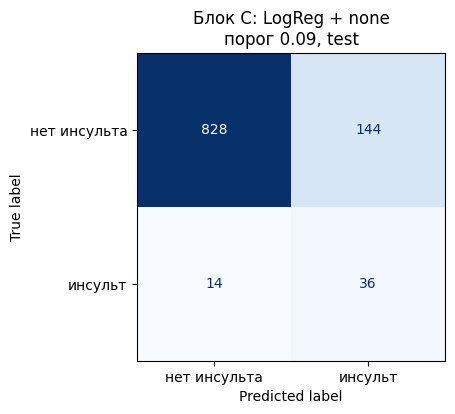

In [30]:
fig, ax = plt.subplots(figsize=(4.8, 4))
ConfusionMatrixDisplay(cm_c, display_labels=["нет инсульта", "инсульт"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Блок C: {final_c_name} + {final_c_method}\nпорог {thr_c:.2f}, test")
plt.show()

## C3. Анализ ошибок: на каких группах пациентов модель ошибается чаще

Чтобы групп было побольше и оценки были устойчивее, берём **всех 5110 пациентов**. Для каждого прогноз получен моделью, которая его **не видела**: для train это честные прогнозы из кросс-валидации, для test это прогноз итоговой модели. Порог один и тот же.

Для каждой группы смотрим:
- **recall** (какую долю больных в группе мы нашли), обратная сторона это доля пропущенных;
- **FP-rate** (какая доля здоровых в группе отправлена на обследование зря);
- число больных в группе. Если их мало, выводы шаткие.

In [31]:
ev = pd.concat([
    XB_train.assign(stroke=y_train, proba=p_oof_c),
    XB_test.assign(stroke=y_test, proba=proba_c),
])
ev["flagged"] = (ev["proba"] >= thr_c).astype(int)

ev["возраст"]  = pd.cut(ev["age"], [-1, 17, 39, 54, 64, 74, 100], labels=["0-17", "18-39", "40-54", "55-64", "65-74", "75+"])
ev["глюкоза"]  = pd.cut(ev["avg_glucose_level"], [0, 100, 140, 200, 400], labels=["<100", "100-140", "140-200", ">200"])
ev["ИМТ"]      = pd.cut(ev["bmi"], [0, 18.5, 25, 30, 100], labels=["<18.5", "18.5-25", "25-30", ">30"]).astype(object).fillna("bmi пропущен")
ev["пол"], ev["гипертония"] = ev["gender"], ev["hypertension"].map({0: "нет", 1: "да"})
ev["болезнь сердца"], ev["в браке"] = ev["heart_disease"].map({0: "нет", 1: "да"}), ev["ever_married"]
ev["курение"], ev["тип работы"] = ev["smoking_status"], ev["work_type"]

def group_table(col):
    rows = []
    for g, d in ev.groupby(col, observed=True):
        pos, neg = d[d.stroke == 1], d[d.stroke == 0]
        rows.append({"признак": col, "группа": str(g), "пациентов": len(d), "инсультов": len(pos),
                     "recall, %": round(pos.flagged.mean() * 100, 1) if len(pos) else np.nan,
                     "пропущено (FN)": int((pos.flagged == 0).sum()),
                     "FP-rate, %": round(neg.flagged.mean() * 100, 1) if len(neg) else np.nan,
                     "отправлено, %": round(d.flagged.mean() * 100, 1)})
    return pd.DataFrame(rows)

group_cols = ["возраст", "пол", "гипертония", "болезнь сердца", "курение", "ИМТ", "глюкоза", "тип работы", "в браке"]
errors = pd.concat([group_table(c) for c in group_cols], ignore_index=True)
errors = errors[errors["группа"] != "Other"]          # группа из 1 человека ничего не говорит
errors.set_index(["признак", "группа"])

                                пациентов  инсультов  recall, %  пропущено (FN)  FP-rate, %  отправлено, %
признак        группа                                                                                     
возраст        0-17                   856          2        0.0               2         0.0            0.0
               18-39                 1314          6        0.0               6         0.0            0.0
               40-54                 1161         29        3.4              28         1.9            1.9
               55-64                  752         53       34.0              35         8.0            9.8
               65-74                  509         57       78.9              12        55.8           58.3
               75+                    518        102      100.0               0        98.1           98.5
пол            Female                2994        141       65.2              49        14.7           17.1
               Male                  

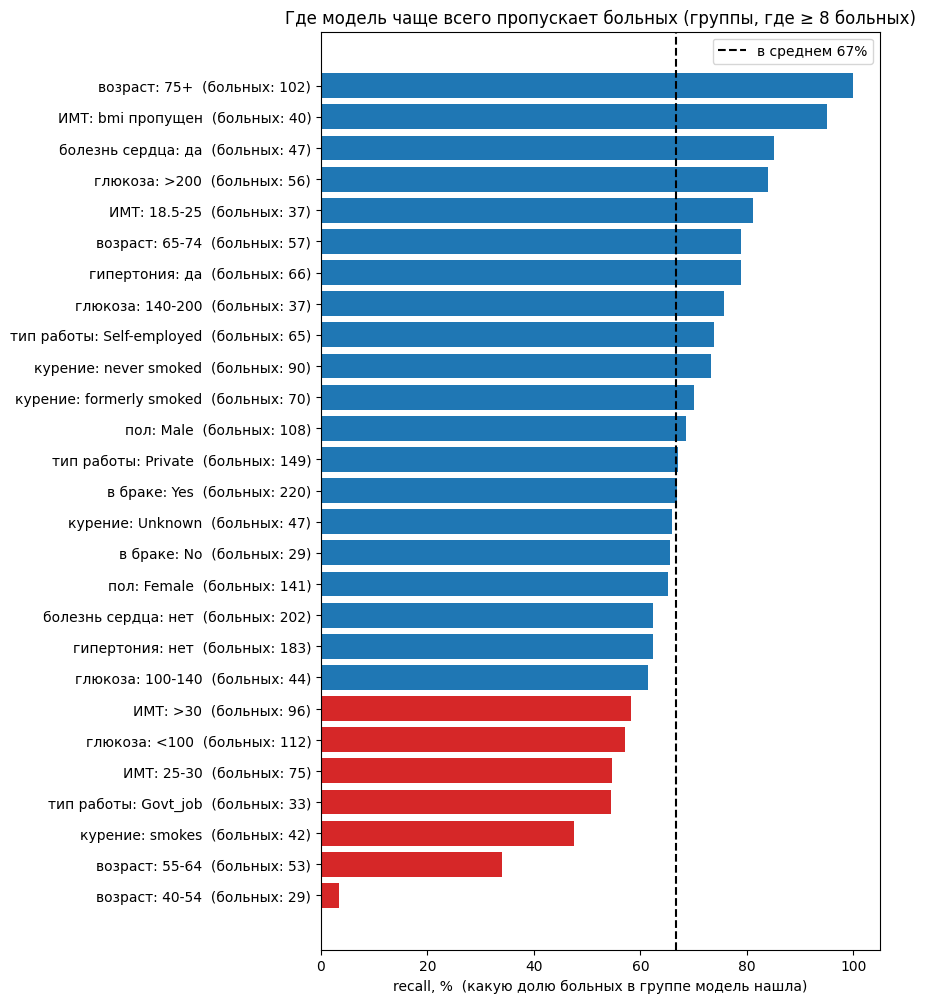

In [32]:
plot_df = errors[(errors["инсультов"] >= 8)].copy()
plot_df["подпись"] = plot_df["признак"] + ": " + plot_df["группа"] + "  (больных: " + plot_df["инсультов"].astype(str) + ")"
plot_df = plot_df.sort_values("recall, %")

fig, ax = plt.subplots(figsize=(9, 0.32 * len(plot_df) + 1.5))
overall = recall_score(ev["stroke"], ev["flagged"]) * 100
ax.barh(plot_df["подпись"], plot_df["recall, %"], color=np.where(plot_df["recall, %"] < overall - 8, "tab:red", "tab:blue"))
ax.axvline(overall, color="k", ls="--", label=f"в среднем {overall:.0f}%")
ax.set_xlabel("recall, %  (какую долю больных в группе модель нашла)"); ax.set_title("Где модель чаще всего пропускает больных (группы, где ≥ 8 больных)")
ax.legend(); plt.tight_layout(); plt.show()

In [33]:
fn_total = int(((ev.stroke == 1) & (ev.flagged == 0)).sum())
print(f"Всего пропущено больных: {fn_total} из {int(ev.stroke.sum())}")
print()
print("Кто чаще всего оказывается среди пропущенных (FN):")
missed = ev[(ev.stroke == 1) & (ev.flagged == 0)]
print("  возраст:", missed["возраст"].value_counts().sort_index().to_dict())
print("  гипертония:", missed["гипертония"].value_counts().to_dict(), "| болезнь сердца:", missed["болезнь сердца"].value_counts().to_dict())
print("  медианный возраст пропущенных:", missed["age"].median(), "| больных вообще:", ev.loc[ev.stroke == 1, "age"].median())

Всего пропущено больных: 83 из 249

Кто чаще всего оказывается среди пропущенных (FN):
  возраст: {'0-17': 2, '18-39': 6, '40-54': 28, '55-64': 35, '65-74': 12, '75+': 0}
  гипертония: {'нет': 69, 'да': 14} | болезнь сердца: {'нет': 76, 'да': 7}
  медианный возраст пропущенных: 57.0 | больных вообще: 71.0


### Что показал анализ ошибок

1. **Модель по сути работает как «фильтр по возрасту».** Молодым она почти никогда не ставит риск: у **0%** пациентов до 40 лет и лишь у 2% в возрасте 40–54. А среди 75+ она отправляет на обследование **98,5%** (все подряд), среди 65–74 примерно 58%. На пожилых приходится около 90% всех направлений.
2. **Больше всего пропусков у людей младше 65 лет.** Из 83 пропущенных больных **71 моложе 65** (28 в группе 40–54, 35 в группе 55–64). Если у человека инсульт случился «рано», модель его почти не видит, потому что в данных таких случаев очень мало (всего 37 инсультов до 55 лет).
3. **Инсульты без известных факторов риска пропускаются чаще.** Recall у людей без гипертонии 62% (против 79% с гипертонией), без болезни сердца 62% (против 85%).
4. **Курильщики** (`smokes`) имеют самый низкий recall среди статусов курения (**48%**). Объяснение, скорее всего, в возрасте: курильщики с инсультом заметно моложе остальных (медианный возраст 61 год против ~72), а молодых модель пропускает. Это гипотеза, не доказанный факт.
5. **Среди пожилых модель не различает пациентов:** при 75+ и recall, и доля «лишних» направлений близки к 100%. Для первичного отбора можно дополнительно сортировать пожилых по вероятности (`proba`), чтобы приоритет получали самые рискованные.
6. **Пол** почти не влияет на ошибки (recall 65% у женщин и 69% у мужчин).
7. **Группа «bmi пропущен»:** recall 95%, но и 55% здоровых из неё отправлено на обследование. Это следствие флага пропуска (см. эксперимент 2): модель «подозревает» всех, у кого bmi не измерен.
8. **Осторожно с малыми группами.** В части групп (дети, 18–39 лет) всего 2–6 больных, на таких числах выводы шаткие.

## C4. Ограничения решения

**Про данные**
- **Мало больных:** всего 249 случаев инсульта (на тесте 50). Доверительный интервал для recall широкий (60–84%), а разница между моделями и методами на таком объёме часто тонет в шуме.
- **Неизвестное происхождение данных.** Мы не знаем, в какой клинике, стране и в какие годы они собраны. Нет внешней проверки: на данных вашей поликлиники качество может быть другим.
- **Цель «был инсульт» это прошлое, а не будущее.** Датасет показывает, у кого инсульт *уже случился*. Мы не знаем, когда измеряли давление, глюкозу и курение: до или после инсульта. Если после, часть признаков это следствие болезни (утечка по времени). Для настоящей оценки «риска в ближайшие годы» нужны данные наблюдения за пациентами во времени.
- **Скрытые пропуски и артефакты:** 30% `Unknown` в курении и особый смысл пропуска `bmi`.
- Нет важных факторов риска: артериальное давление в цифрах, холестерин, наследственность, физическая активность, приём лекарств.

**Про модель**
- **Опора на возраст.** Модель плохо находит молодых больных и почти не различает пожилых между собой.
- **Низкая точность отбора:** около 80% направленных здоровы. При дешёвом обследовании это допустимо, но нужно подтвердить, что поликлиника выдержит нагрузку (около 18% пациентов).
- **Пропускаем около 28% больных.** Любой пациент с симптомами должен получать помощь независимо от решения модели.
- **Порог и метрика (F2) выбраны нами** на предположении, что пропуск намного опаснее лишнего обследования. Реальное соотношение цены ошибок и возможности поликлиники нужно уточнить у заказчика и подобрать порог под них.
- Порог подбирали по тем же данным кросс-валидации, поэтому оценка немного оптимистична. Калибровку вероятностей не проверяли.

**Про применение**
- Модель **не диагностическое средство.** Это вспомогательный фильтр, окончательное решение принимает врач.
- Перед внедрением нужна проверка на новых пациентах, регулярный контроль качества и учёт того, что состав пациентов со временем меняется.
- Нужно соблюдать конфиденциальность медицинских данных.

---
## Общий итог

| | Блок A | Блок B | Блок C |
|---|---|---|---|
| Что сделали | базовая LogReg, порог 0.5 | Pipeline, 2 модели, CV, F2, порог | утечки, балансировка, анализ ошибок |
| Найдено больных на тесте | 1 из 50 | **36 из 50** | **36 из 50** (доверительный интервал 60–84%) |
| Главный урок | accuracy обманывает при дисбалансе | порог и метрика важнее выбора модели | баланс и сложные методы не дали выигрыша, а модель опирается на возраст |

**Рекомендация заказчику:** использовать модель как первый фильтр (LogReg, порог ≈ 0.09) с оговорками выше, обязательно уточнить цену ошибок и мощность поликлиники и собрать данные с наблюдением во времени, чтобы научиться предсказывать будущий риск, а не «был ли уже инсульт».